# EIA-861M Monthly Electricity Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

FILE_OLD = "data/raw/HS861M 1990-2009.xlsx"
FILE_NEW = "data/raw/HS861M 2010-.xlsx"

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


**How to run:** open this notebook from the project's main folder so the `data/` paths work. Run all cells in order.

In [3]:
# Both files have a 3-row merged header; skip to the third row for column names
def load_eia861m(path):
    df = pd.read_excel(path, sheet_name=0, header=2)
    return df

old = load_eia861m(FILE_OLD)
new = load_eia861m(FILE_NEW)

print("Old shape:", old.shape)
print("New shape:", new.shape)
# old.head(3)

# Rename the first four columns consistently across both files
def rename_base_cols(df):
    cols = list(df.columns)
    cols[:4] = ["year", "month", "state", "data_status"]
    df.columns = cols
    return df

old = rename_base_cols(old)
new = rename_base_cols(new)

# Stack them
df = pd.concat([old, new], ignore_index=True)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"])
df["year"] = df["year"].astype(int)

print("Combined shape:", df.shape)
print("Year range:", df['year'].min(), "-", df['year'].max())

price_cols = {"year": df.columns[0],
              "month": df.columns[1],
              "state": df.columns[2],
              "data_status": df.columns[3],
              "res_sales": df.columns[5],
              "res_price": df.columns[7],
              "com_sales": df.columns[9],
              "com_price": df.columns[11],
              "ind_sales": df.columns[13],
              "ind_price": df.columns[15],
              "total_price": df.columns[-1]}

df = df[list(price_cols.values())].copy()
df.columns = list(price_cols.keys())

price_col_names = ["res_sales", "res_price", "com_sales",
                   "com_price", "ind_sales", "ind_price", "total_price"]

df[price_col_names] = df[price_col_names].replace(".", np.nan)
df[price_col_names] = df[price_col_names].apply(pd.to_numeric, errors="coerce")

print("Missing values per column:")
print(df[price_col_names].isna().sum())

STATES = ["VA", "MD", "NC", "TX", "CA", "US"]

df_states = df[df["state"].isin(STATES)].copy()

print("Filtered shape:", df_states.shape)
print("States included:", sorted(df_states["state"].unique()))

df_states["date"] = pd.to_datetime(
    df_states[["year", "month"]].assign(day=1)
)

df_states = df_states.sort_values(["state", "date"]).reset_index(drop=True)
df_states.head()

# Check for duplicate state/month/year combos
dupes = df_states.duplicated(subset=["state", "year", "month"])
print(f"Duplicate rows: {dupes.sum()}")

Old shape: (12241, 28)
New shape: (10201, 24)
Combined shape: (22440, 28)
Year range: 1990 - 2026
Missing values per column:
res_sales          0
res_price          0
com_sales         13
com_price         13
ind_sales         13
ind_price         13
total_price    10200
dtype: int64
Filtered shape: (2200, 11)
States included: ['CA', 'MD', 'NC', 'TX', 'VA']
Duplicate rows: 0


In [4]:
OUT = "data/clean/monthly_eia861m_clean.csv"
df_states.to_csv(OUT, index=False)
print(f"Saved {len(df_states):,} rows to {OUT}")

Saved 2,200 rows to data/clean/monthly_eia861m_clean.csv


Figures

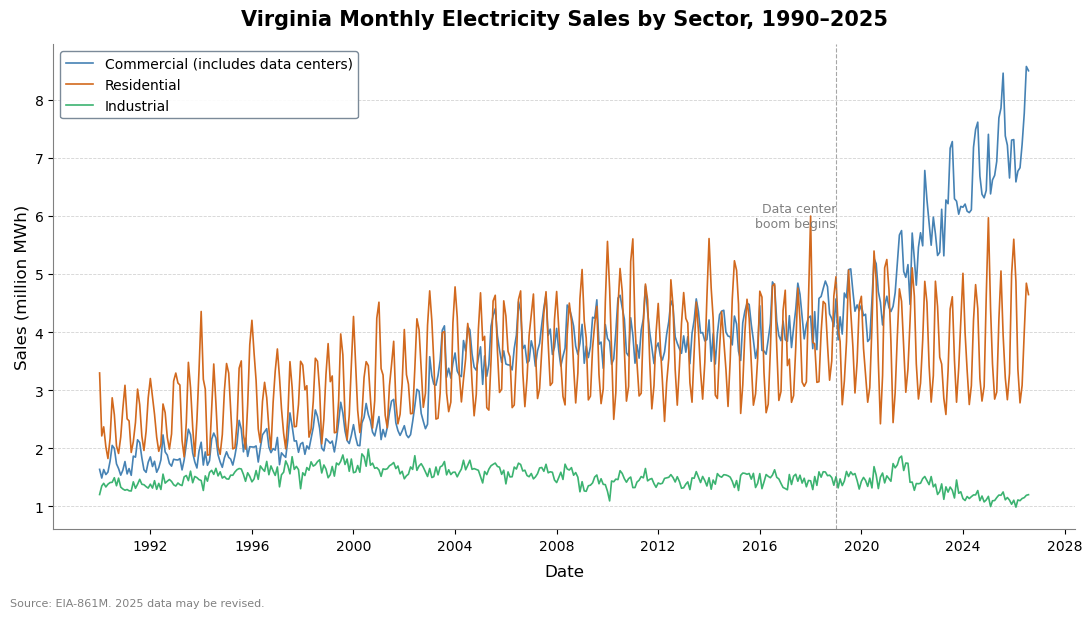

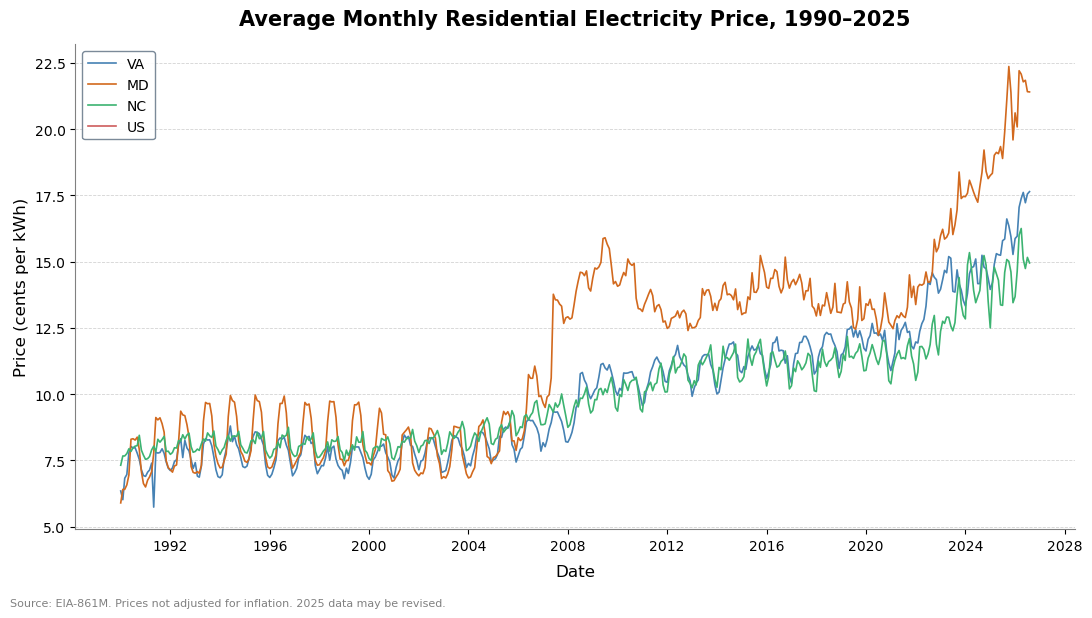

In [5]:
df = pd.read_csv("data/clean/monthly_eia861m_clean.csv", parse_dates=["date"])

def plot_monthly_sales(df):
    va = df[df["state"] == "VA"]

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.plot(va["date"], va["com_sales"] / 1e6, color="steelblue",
            linewidth=1.2, label="Commercial (includes data centers)")
    ax.plot(va["date"], va["res_sales"] / 1e6, color="chocolate",
            linewidth=1.2, label="Residential")
    ax.plot(va["date"], va["ind_sales"] / 1e6, color="mediumseagreen",
            linewidth=1.2, label="Industrial")

    ax.axvline(x=pd.Timestamp("2019-01-01"), color="grey",
               linestyle="--", linewidth=0.8, alpha=0.7)
    ax.annotate("Data center\nboom begins",
                xy=(pd.Timestamp("2019-01-01"), 6), fontsize=9,
                color="grey", ha="right", va="center")

    ax.set_title("Virginia Monthly Electricity Sales by Sector, 1990–2025",
                 fontsize=15, fontweight="bold", pad=14)
    ax.set_xlabel("Date", fontsize=12, labelpad=8)
    ax.set_ylabel("Sales (million MWh)", fontsize=12)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines["bottom"].set_color("grey")
    ax.spines["left"].set_color("grey")
    ax.yaxis.grid(True, color="lightgrey", linewidth=0.6, linestyle="--")
    ax.set_axisbelow(True)
    ax.legend(fontsize=10, frameon=True, framealpha=0.92, edgecolor="slategrey")
    fig.text(0.01, -0.02, "Source: EIA-861M. 2025 data may be revised.",
             fontsize=8, color="grey")

    plt.tight_layout()
    plt.savefig("figures/fig1_monthly_va_sales_by_sector.png",
                dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()


def plot_monthly_prices(df):
    state_colors = {"VA": "steelblue", "MD": "chocolate",
                    "NC": "mediumseagreen", "US": "indianred"}

    fig, ax = plt.subplots(figsize=(11, 6))

    for state, color in state_colors.items():
        s = df[df["state"] == state]
        ax.plot(s["date"], s["res_price"], color=color,
                linewidth=1.2, label=state)

    ax.set_title("Average Monthly Residential Electricity Price, 1990–2025",
                 fontsize=15, fontweight="bold", pad=14)
    ax.set_xlabel("Date", fontsize=12, labelpad=8)
    ax.set_ylabel("Price (cents per kWh)", fontsize=12)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines["bottom"].set_color("grey")
    ax.spines["left"].set_color("grey")
    ax.yaxis.grid(True, color="lightgrey", linewidth=0.6, linestyle="--")
    ax.set_axisbelow(True)
    ax.legend(fontsize=10, frameon=True, framealpha=0.92, edgecolor="slategrey")
    fig.text(0.01, -0.02,
             "Source: EIA-861M. Prices not adjusted for inflation. 2025 data may be revised.",
             fontsize=8, color="grey")

    plt.tight_layout()
    plt.savefig("figures/fig2_monthly_residential_prices.png",
                dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()


plot_monthly_sales(df)
plot_monthly_prices(df)